# Exercises 1–2 · MNIST above 97%, then data augmentation

**Book:** Chapter 3, Exercises 1 and 2

**Task:** (1) beat 97% test accuracy with a tuned KNN; (2) add four one-pixel-shifted copies of every training image and retrain.

The grid search runs on 10,000 images; final models are trained on the full set.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.ndimage import shift
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

from homl.datasets import load_mnist
from homl.plotting import RANDOM_STATE, save_fig

X, y = load_mnist()
X = X.astype(np.float32)  # halves memory
X_train, X_test, y_train, y_test = X[:60_000], X[60_000:], y[:60_000], y[60_000:]

## Baseline
Default KNN on all 60,000 images.

In [2]:
baseline = KNeighborsClassifier(n_jobs=-1).fit(X_train, y_train)
baseline_acc = accuracy_score(y_test, baseline.predict(X_test))
print(f"baseline test accuracy: {baseline_acc:.4f}")

baseline test accuracy: 0.9688


## Exercise 1 — hyperparameter search

In [3]:
param_grid = {"weights": ["uniform", "distance"], "n_neighbors": [3, 4, 5, 6]}
grid = GridSearchCV(KNeighborsClassifier(), param_grid, cv=3, n_jobs=-1)
grid.fit(X_train[:10_000], y_train[:10_000])
cv_table = pd.DataFrame(grid.cv_results_)[["param_weights", "param_n_neighbors", "mean_test_score"]]
cv_table.sort_values("mean_test_score", ascending=False).head(8).round(4)

,param_weights,param_n_neighbors,mean_test_score
3,distance,4,0.9398
1,distance,3,0.9385
7,distance,6,0.9373
5,distance,5,0.9370
0,uniform,3,0.9354
2,uniform,4,0.9348
4,uniform,5,0.9332
6,uniform,6,0.9318


In [4]:
print("best params:", grid.best_params_)
best_knn = KNeighborsClassifier(**grid.best_params_, n_jobs=-1).fit(X_train, y_train)
tuned_acc = accuracy_score(y_test, best_knn.predict(X_test))
print(f"tuned KNN test accuracy (trained on 60k): {tuned_acc:.4f}")

best params: {'n_neighbors': 4, 'weights': 'distance'}


tuned KNN test accuracy (trained on 60k): 0.9714


## Exercise 2 — shifting images
Pixels entering from the border are set to 0 (background).

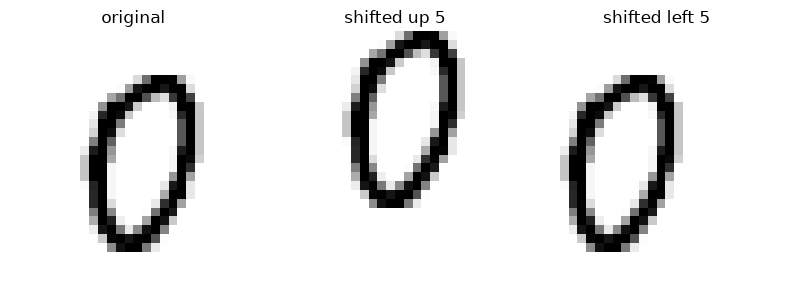

In [5]:
def shift_image(image: np.ndarray, dx: int, dy: int) -> np.ndarray:
    """Shift a flattened 28x28 image by dx pixels right and dy pixels down."""
    shifted = shift(image.reshape(28, 28), [dy, dx], cval=0, mode="constant")
    return shifted.reshape(-1).astype(image.dtype)


image = X_train[1000]
fig, axes = plt.subplots(1, 3, figsize=(8, 3))
for ax, (img, title) in zip(axes, [(image, "original"), (shift_image(image, 0, -5), "shifted up 5"),
                                   (shift_image(image, -5, 0), "shifted left 5")]):
    ax.imshow(img.reshape(28, 28), cmap="binary"); ax.set_title(title); ax.axis("off")
save_fig("shifted_digit")
plt.show()

Four shifts per image turn 60,000 training images into 300,000.

In [6]:
X_aug = [X_train]
y_aug = [y_train]
for dx, dy in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
    X_aug.append(np.apply_along_axis(shift_image, 1, X_train, dx, dy))
    y_aug.append(y_train)
X_aug = np.concatenate(X_aug)
y_aug = np.concatenate(y_aug)
perm = np.random.default_rng(RANDOM_STATE).permutation(len(X_aug))
X_aug, y_aug = X_aug[perm], y_aug[perm]
print(X_aug.shape)

(300000, 784)


In [7]:
aug_knn = KNeighborsClassifier(**grid.best_params_, n_jobs=-1).fit(X_aug, y_aug)
aug_acc = accuracy_score(y_test, aug_knn.predict(X_test))
print(f"tuned KNN on augmented set, test accuracy: {aug_acc:.4f}")

tuned KNN on augmented set, test accuracy: 0.9763


## Results

In [8]:
results = pd.DataFrame(
    {
        "model": ["KNN default (60k)", f"KNN tuned {grid.best_params_} (60k)", "KNN tuned + shift augmentation (300k)"],
        "test accuracy": [baseline_acc, tuned_acc, aug_acc],
    }
)
results["error rate"] = 1 - results["test accuracy"]
results.round(4)

,model,test accuracy,error rate
0,KNN default (60k),0.9688,0.0312
1,"KNN tuned {'n_neighbors': 4, 'weights': 'dista...",0.9714,0.0286
2,KNN tuned + shift augmentation (300k),0.9763,0.0237


**Takeaways**
- Distance-weighted KNN with 4 neighbors clears 97% (97.14%) with no feature engineering.
- Shift augmentation raises it to 97.63% by making the model tolerant of small translations.
- The cost: 5× the memory and prediction time, since KNN stores the whole training set.